Loading 3000 patients for train...
Created 1291 training windows of shape (1291, 48, 5)
Starting Training...
Created 1291 training windows of shape (1291, 48, 5)
Starting Training...
Epoch 1/30 | Loss: 0.03676
Epoch 1/30 | Loss: 0.03676
Epoch 2/30 | Loss: 0.01666
Epoch 2/30 | Loss: 0.01666
Epoch 3/30 | Loss: 0.01484
Epoch 3/30 | Loss: 0.01484
Epoch 4/30 | Loss: 0.01423
Epoch 4/30 | Loss: 0.01423
Epoch 5/30 | Loss: 0.01359
Epoch 5/30 | Loss: 0.01359
Epoch 6/30 | Loss: 0.01251
Epoch 6/30 | Loss: 0.01251
Epoch 7/30 | Loss: 0.01118
Epoch 7/30 | Loss: 0.01118
Epoch 8/30 | Loss: 0.01165
Epoch 8/30 | Loss: 0.01165
Epoch 9/30 | Loss: 0.01169
Epoch 9/30 | Loss: 0.01169
Epoch 10/30 | Loss: 0.01087
Epoch 10/30 | Loss: 0.01087
Epoch 11/30 | Loss: 0.01190
Epoch 11/30 | Loss: 0.01190
Epoch 12/30 | Loss: 0.01146
Epoch 12/30 | Loss: 0.01146
Epoch 13/30 | Loss: 0.00999
Epoch 13/30 | Loss: 0.00999
Epoch 14/30 | Loss: 0.01046
Epoch 14/30 | Loss: 0.01046
Epoch 15/30 | Loss: 0.01141
Epoch 15/30 | Loss: 0.0

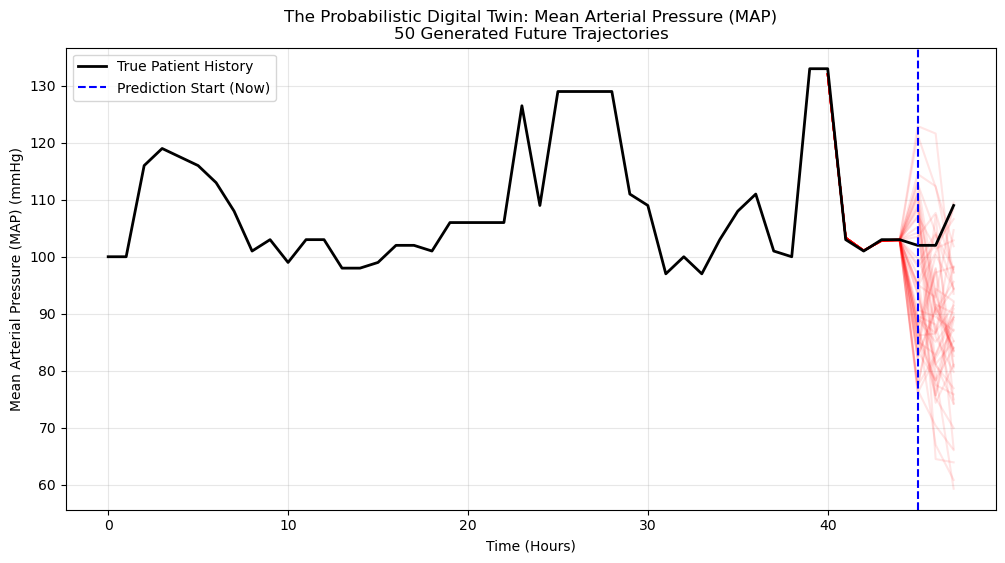

Done! If you see a spread of red lines, that is the uncertainty envelope.


In [5]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import math

# ==========================================
# 0. Configuration
# ==========================================
CONFIG = {
    "DATA_PATH": "./training_setA",  # Local folder (or update to your path)
    "VITALS": ['HR', 'MAP', 'O2Sat', 'SBP', 'Resp'],
    "SEQ_LEN": 48,      # Total window size (e.g., 48 hours)
    "PRED_LEN": 3,      # How many hours to predict into the future
    "BATCH_SIZE": 32,
    "HIDDEN_DIM": 128,
    "DIFFUSION_STEPS": 100,
    "EPOCHS": 30,       # Keep low for MVP presentation
    "MAX_FILES": 3000   # Limit dataset size for speed (MVP mode)
}

# Vital sign display info
VITAL_INFO = {
    'HR': {'name': 'Heart Rate', 'unit': 'bpm', 'scale': 100},
    'MAP': {'name': 'Mean Arterial Pressure', 'unit': 'mmHg', 'scale': 100},
    'O2Sat': {'name': 'Oxygen Saturation', 'unit': '%', 'scale': 100},
    'SBP': {'name': 'Systolic Blood Pressure', 'unit': 'mmHg', 'scale': 140},
    'Resp': {'name': 'Respiratory Rate', 'unit': 'breaths/min', 'scale': 20}
}

# ==========================================
# 1. Dataset Loader (Handling the .psv)
# ==========================================
class SepsisDataset(Dataset):
    def __init__(self, data_dir, config, mode='train'):
        self.files = sorted([f for f in os.listdir(data_dir) if f.endswith('.psv')])
        # MVP: Limit to first N files to save time
        self.files = self.files[:config["MAX_FILES"]]
        self.data_dir = data_dir
        self.vitals = config["VITALS"]
        self.seq_len = config["SEQ_LEN"]
        self.data_cache = []

        print(f"Loading {len(self.files)} patients for {mode}...")

        # Pre-load and process valid windows
        for f in self.files:
            df = pd.read_csv(os.path.join(data_dir, f), sep='|')

            # Select vitals
            df = df[self.vitals]

            # 1. Handle Missing Data (Crucial for Medical Time Series)
            # Forward fill first (carry last observation forward)
            df = df.ffill()
            # Backward fill next (for missing initial values)
            df = df.bfill()
            # If any NaNs remain (empty columns), fill with global defaults
            df = df.fillna(0)

            # 2. Normalize (Simple Min-Max or Z-score)
            # Using simple approx constants for ICU vitals to keep it stable
            # HR:60-100, MAP:60-100, O2:90-100, SBP:90-140, Resp:12-20
            norm_vals = {'HR': 100, 'MAP': 100, 'O2Sat': 100, 'SBP': 140, 'Resp': 20}
            for v in self.vitals:
                df[v] = df[v] / norm_vals[v]

            data = df.values.astype(np.float32)

            # 3. Create Sliding Windows
            # We need at least SEQ_LEN hours of data
            if len(data) >= self.seq_len:
                # Just take the LAST window for each patient to keep dataset balanced for MVP
                # Or slide across:
                for i in range(0, len(data) - self.seq_len + 1, 12): # Stride of 12
                    window = data[i : i + self.seq_len]
                    self.data_cache.append(window)

        self.data_cache = np.array(self.data_cache)
        print(f"Created {len(self.data_cache)} training windows of shape {self.data_cache.shape}")

    def __len__(self):
        return len(self.data_cache)

    def __getitem__(self, idx):
        # Shape: (Seq_Len, Channels) -> Transpose to (Channels, Seq_Len) for PyTorch Conv1d
        sample = self.data_cache[idx]
        return torch.tensor(sample).transpose(0, 1)

# ==========================================
# 2. The Diffusion Model (Time-Series Optimized)
# ==========================================
class SinusoidalEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

class ResidualBlock(nn.Module):
    def __init__(self, channels, time_emb_dim):
        super().__init__()
        self.conv1 = nn.Conv1d(channels, channels, 3, padding=1)
        self.conv2 = nn.Conv1d(channels, channels, 3, padding=1)
        self.time_mlp = nn.Linear(time_emb_dim, channels)
        self.bn = nn.BatchNorm1d(channels)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, t):
        h = self.conv1(self.act(x))
        time_emb = self.time_mlp(self.act(t)).unsqueeze(-1)
        h = h + time_emb
        h = self.conv2(self.act(h))
        return self.bn(h + x)

class MedicalDiffusion(nn.Module):
    def __init__(self, num_channels, seq_len, hidden_dim=64):
        super().__init__()
        self.time_emb = SinusoidalEmbedding(hidden_dim)

        # Input: Channels + Mask (Conditioning)
        self.input_proj = nn.Conv1d(num_channels * 2, hidden_dim, 1)

        self.res1 = ResidualBlock(hidden_dim, hidden_dim)
        self.res2 = ResidualBlock(hidden_dim, hidden_dim)
        self.res3 = ResidualBlock(hidden_dim, hidden_dim)
        self.res4 = ResidualBlock(hidden_dim, hidden_dim)

        self.output_proj = nn.Conv1d(hidden_dim, num_channels, 1)

    def forward(self, x, mask, t):
        # x: Noisy observation
        # mask: 1 for Observed (Past), 0 for Missing (Future)

        # Concatenate Input with Mask so model knows what is "Real" and what is "Hallucination"
        x_in = torch.cat([x, mask], dim=1)

        t_emb = self.time_emb(t)

        h = self.input_proj(x_in)
        h = self.res1(h, t_emb)
        h = self.res2(h, t_emb)
        h = self.res3(h, t_emb)
        h = self.res4(h, t_emb)

        return self.output_proj(h)

# ==========================================
# 3. Training & Inference Logic
# ==========================================
def get_beta_schedule(steps):
    return torch.linspace(0.0001, 0.02, steps)

def train_model():
    dataset = SepsisDataset(CONFIG["DATA_PATH"], CONFIG)
    dataloader = DataLoader(dataset, batch_size=CONFIG["BATCH_SIZE"], shuffle=True)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MedicalDiffusion(len(CONFIG["VITALS"]), CONFIG["SEQ_LEN"], CONFIG["HIDDEN_DIM"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(device)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    print("Starting Training...")
    model.train()

    for epoch in range(CONFIG["EPOCHS"]):
        total_loss = 0
        for batch in dataloader:
            batch = batch.to(device) # Shape: (B, Channels, Time)

            # Create Mask: Hide the last PRED_LEN hours (The "Future")
            mask = torch.ones_like(batch)
            mask[:, :, -CONFIG["PRED_LEN"]:] = 0

            # Add Noise
            noise = torch.randn_like(batch)
            t = torch.randint(0, CONFIG["DIFFUSION_STEPS"], (batch.shape[0],), device=device)

            alpha_bar = alphas_cumprod[t].reshape(-1, 1, 1)
            noisy_input = torch.sqrt(alpha_bar) * batch + torch.sqrt(1 - alpha_bar) * noise

            # IMPUTATION CONDITIONING:
            # The model sees: (Masked Real Data) + (Noisy Future)
            model_input = mask * batch + (1 - mask) * noisy_input

            # Predict
            pred_noise = model(model_input, mask, t)

            # Loss only on the FUTURE (the missing part)
            loss = F.mse_loss(pred_noise * (1-mask), noise * (1-mask))

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{CONFIG['EPOCHS']} | Loss: {total_loss/len(dataloader):.5f}")

    return model, dataset

def generate_digital_twin(model, patient_data, device):
    """
    patient_data: (Channels, Time)
    Generates 50 possible futures for this patient.
    """
    model.eval()
    n_samples = 50
    seq_len = patient_data.shape[1]

    # Repeat patient data 50 times
    x = patient_data.unsqueeze(0).repeat(n_samples, 1, 1).to(device)

    # Mask the future
    mask = torch.ones_like(x)
    mask[:, :, -CONFIG["PRED_LEN"]:] = 0

    # Start with pure noise
    curr_img = torch.randn_like(x).to(device)

    betas = get_beta_schedule(CONFIG["DIFFUSION_STEPS"]).to(device)
    alphas = 1. - betas
    alphas_cumprod = torch.cumprod(alphas, dim=0)

    for t in reversed(range(CONFIG["DIFFUSION_STEPS"])):
        # Conditioning: Always reset the PAST to the known ground truth
        curr_img = mask * x + (1 - mask) * curr_img

        t_tensor = torch.full((n_samples,), t, device=device, dtype=torch.long)

        with torch.no_grad():
            pred_noise = model(curr_img, mask, t_tensor)

        alpha = alphas[t]
        alpha_bar = alphas_cumprod[t]
        beta = betas[t]

        if t > 0:
            z = torch.randn_like(curr_img)
        else:
            z = 0

        # DDPM update
        curr_img = (1 / torch.sqrt(alpha)) * (curr_img - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * pred_noise) + torch.sqrt(beta) * z

    return curr_img.cpu().numpy()

# ==========================================
# 4. Main Execution & Visualization
# ==========================================
if __name__ == "__main__":
    # Check if data exists
    if not os.path.exists(CONFIG["DATA_PATH"]):
        print("Error: Data path not found. Please run the download script first.")
    else:
        # Train
        model, dataset = train_model()

        # Pick a random patient to test
        idx = np.random.randint(0, len(dataset))
        patient_sample = dataset[idx] # (Channels, Time)

        print("\nGenering Digital Twin Futures...")
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        futures = generate_digital_twin(model, patient_sample, device) # (50, Channels, Time)

        # Visualizing 'MAP' (Mean Arterial Pressure) - Index 1 in VITALS list
        vital_idx = 1
        vital_name = "Mean Arterial Pressure (MAP)"

        plt.figure(figsize=(12, 6))

        # Plot 50 generated futures
        # We only plot the FUTURE part (last PRED_LEN steps) + a bit of context
        split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]

        # Un-normalize for display (Multiply by 100 as per our loader)
        scale_factor = 100.0

        # Plot 50 Futures
        for i in range(50):
            plt.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                     futures[i, vital_idx, split_pt-5:] * scale_factor,
                     color='red', alpha=0.1)

        # Plot Ground Truth
        truth = patient_sample[vital_idx] * scale_factor
        plt.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True Patient History")

        # Visuals
        plt.axvline(x=split_pt, color='blue', linestyle='--', label="Prediction Start (Now)")
        plt.title(f"The Probabilistic Digital Twin: {vital_name}\n50 Generated Future Trajectories")
        plt.xlabel("Time (Hours)")
        plt.ylabel(f"{vital_name} (mmHg)")
        plt.legend(loc='upper left')
        plt.grid(True, alpha=0.3)
        plt.show()

        print("Done! If you see a spread of red lines, that is the uncertainty envelope.")

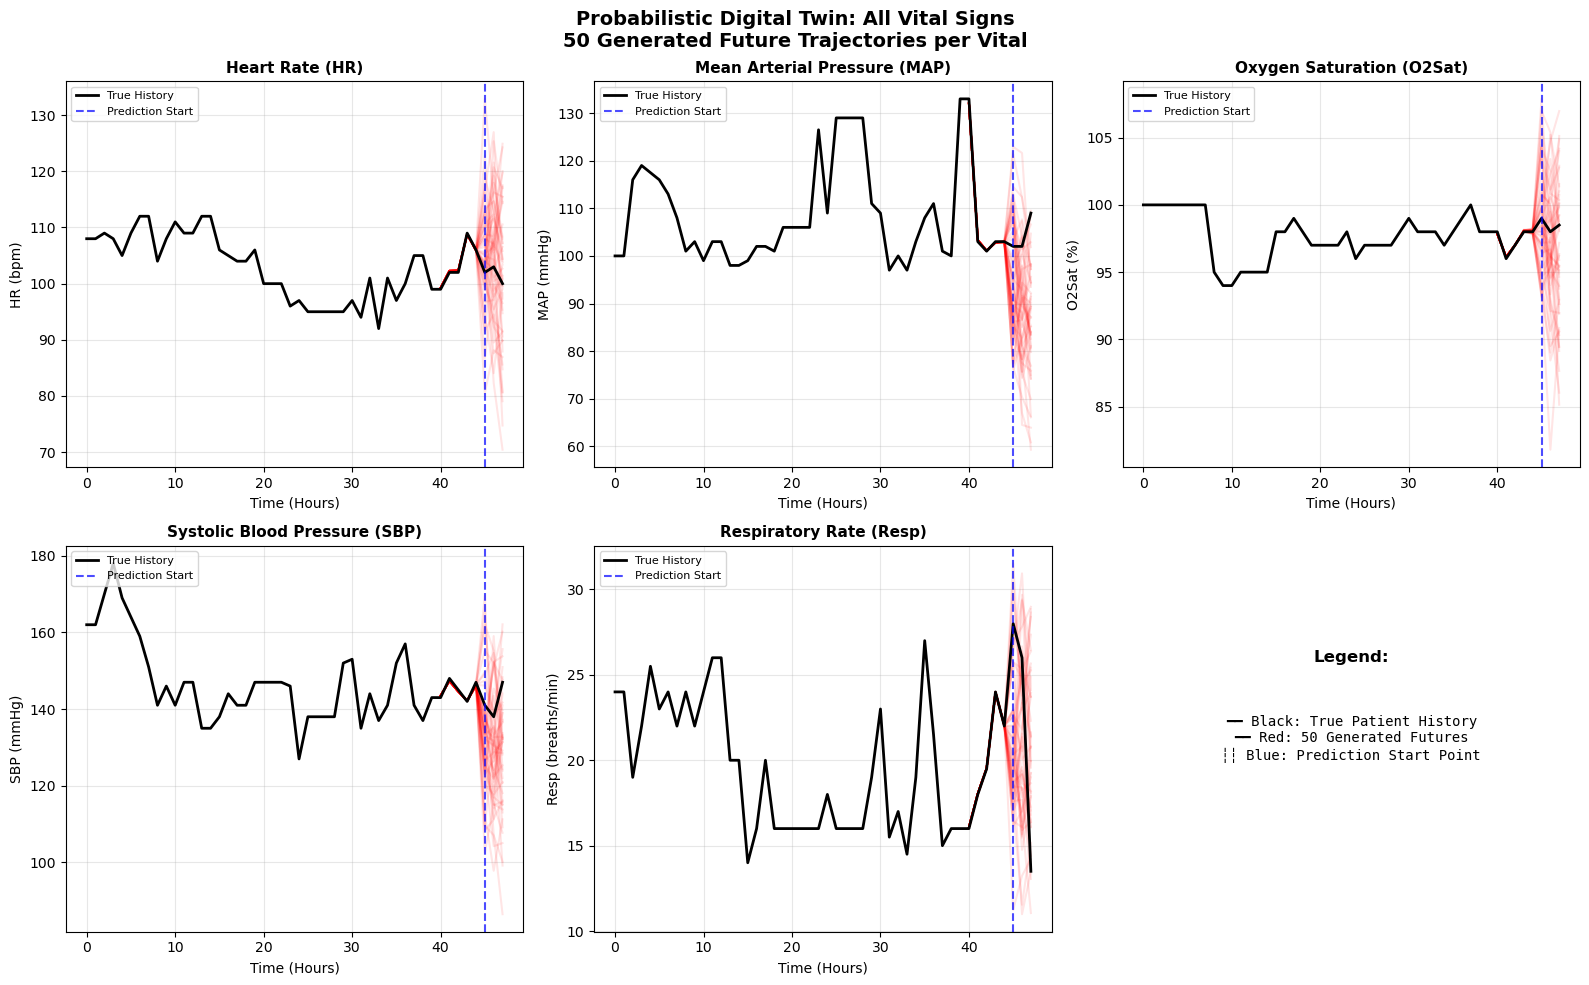


✓ Done! The spread of red lines shows uncertainty in future predictions.
  Wider spread = more uncertainty, Narrow spread = more confident prediction


In [6]:
# ==========================================
# 5. Visualize ALL 5 Vitals (Multi-Plot)
# ==========================================

# Make sure 'model', 'dataset', 'patient_sample', and 'futures' exist from previous cell
# If not, re-run the main cell first

split_pt = CONFIG["SEQ_LEN"] - CONFIG["PRED_LEN"]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for vital_idx, vital_key in enumerate(CONFIG["VITALS"]):
    ax = axes[vital_idx]
    info = VITAL_INFO[vital_key]
    scale_factor = info['scale']
    
    # Plot 50 generated futures (red, semi-transparent)
    for i in range(50):
        ax.plot(range(split_pt-5, CONFIG["SEQ_LEN"]),
                futures[i, vital_idx, split_pt-5:] * scale_factor,
                color='red', alpha=0.1)
    
    # Plot Ground Truth (black line)
    truth = patient_sample[vital_idx].numpy() * scale_factor
    ax.plot(range(CONFIG["SEQ_LEN"]), truth, color='black', linewidth=2, label="True History")
    
    # Prediction start line
    ax.axvline(x=split_pt, color='blue', linestyle='--', alpha=0.7, label="Prediction Start")
    
    # Labels
    ax.set_title(f"{info['name']} ({vital_key})", fontsize=11, fontweight='bold')
    ax.set_xlabel("Time (Hours)")
    ax.set_ylabel(f"{vital_key} ({info['unit']})")
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot (we have 5 vitals)
axes[5].axis('off')

# Add legend explanation in empty subplot
axes[5].text(0.5, 0.7, "Legend:", fontsize=12, fontweight='bold', 
             ha='center', transform=axes[5].transAxes)
axes[5].text(0.5, 0.5, "━━ Black: True Patient History\n"
                       "━━ Red: 50 Generated Futures\n"
                       "┆┆ Blue: Prediction Start Point",
             fontsize=10, ha='center', va='center', transform=axes[5].transAxes,
             family='monospace')

plt.suptitle("Probabilistic Digital Twin: All Vital Signs\n"
             "50 Generated Future Trajectories per Vital", 
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n✓ Done! The spread of red lines shows uncertainty in future predictions.")
print("  Wider spread = more uncertainty, Narrow spread = more confident prediction")